# EnBlockRNN on Venezuela Dengue — Step 2 of 2: final training and test forecasting

This notebook takes the three tuning studies produced by **`enblockrnn-tune.ipynb`** (one run per horizon, run in parallel), merges them, retrains EnBlockRNN with the best settings for each horizon on **train + validation**, and forecasts the test windows for H = 4, 9 and 13 weeks. The benchmarks are run on the same splits.

| Part | Contents |
|---|---|
| 0 | Installation, imports, versions |
| 1 | Configuration (must match the tuning runs) |
| 1b | Forecast head fix and data transform |
| 2–4 | Data, `TimeSeries`, train / validation / test split + leakage checks |
| 4b, 5 | Tensor shapes; M vs. number of prediction samples |
| 6 | Shared helpers |
| 7 | **Collect and merge the three tuning studies**, tuning results |
| 8 | **Final training** on train + validation with the best settings |
| 9 | Training loss curves |
| 10 | **Test forecasts**: 50 repeated ensembles per trained model |
| 11 | Benchmarks on the same splits |
| 12 | Results tables and figures |
| 13 | Save everything |

**Before running:** in Kaggle, **Add Input → Your Work → Notebooks** and add the three tuning notebooks (or upload their `optuna_<horizon>.db` files as a dataset). Part 7 finds them under `/kaggle/input/`.

**Why this has no test leakage.** The test window is never used to fit a model, to fit the scaler, or to choose a setting. Tuning only saw train (to fit) and validation (to score). The final model is fitted on train + validation, and the test weeks are used exactly once, for scoring, at the end. Part 4 asserts this in code.

## Part 0a — Installation

* We use `darts` **0.47.0**: darts 0.48.x moved an internal class and `engressionts 0.1.1` fails to import with it.
* `pytorch-lightning` is required by Darts' torch models but is **not** pulled in by `engressionts` itself.
* `openpyxl` reads the `.xlsx` data file.
* Kaggle already ships `torch`; we do not reinstall it.


In [2]:
%%capture install_log
!pip install -q "darts==0.47.0" "engressionts==0.1.1" pytorch-lightning openpyxl optuna statsforecast

In [3]:
# Show only the tail of the install log (errors would appear here).
# Safe to run after a kernel restart: it just says the log is gone.
if "install_log" in globals():
    print(install_log.stdout[-1500:] or "install finished quietly")
    print(install_log.stderr[-1500:])
else:
    print("No install log in this kernel session (fine after a restart) - continue to Part 1.")

install finished quietly



## Part 0b - Imports and Versions 

Package versions are recorded here and saved at the end of the notebook.

In [4]:
import os, sys, json, time, platform, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner, NopPruner
from optuna.trial import TrialState
import torch.nn as nn

import darts, pytorch_lightning as pl
from darts.models import BlockRNNModel, AutoARIMA, AutoETS, NaiveSeasonal
from darts import TimeSeries
from darts.dataprocessing import Pipeline
from darts.dataprocessing.transformers import Scaler, InvertibleMapper
from sklearn.preprocessing import StandardScaler

import engressionts
import engressionts.base.base_engression as eng_base
from engressionts.models import EnBlockRNNModel
from engressionts.models.enblock_rnn_model import CustomBlockRNNModule as EnCustomBlockRNNModule
from darts.models.forecasting.block_rnn_model import CustomBlockRNNModule as DartsCustomBlockRNNModule
from darts.models.forecasting.pl_forecasting_module import io_processor
from engressionts import metrics as M          # mae, rmse, crps, empirical_coverage, mpiw, winkler_score, ...

warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "darts"]:
    logging.getLogger(name).setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONS = {
    "python": platform.python_version(),
    "engressionts": engressionts.__version__,
    "darts": darts.__version__,
    "pytorch_lightning": pl.__version__,
    "torch": torch.__version__,
    "optuna": optuna.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(json.dumps(VERSIONS, indent=2))
assert darts.__version__.startswith("0.4") and not darts.__version__.startswith("0.48"), \
    "darts 0.48+ breaks engressionts 0.1.1 — rerun Part 0 and restart the kernel"

ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
print("Accelerator:", ACCELERATOR, "|", torch.cuda.get_device_name(0) if ACCELERATOR == "gpu" else "")

{
  "python": "3.13.16",
  "engressionts": "0.1.1",
  "darts": "0.47.0",
  "pytorch_lightning": "2.6.6",
  "torch": "2.11.0+cu130",
  "optuna": "5.0.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
}
Accelerator: gpu | Tesla T4


## Part 1 - Configuration

Everything you might change lives here. These settings **must match the tuning runs**; the merge step (Part 7) compares them with the settings stored in each tuning study and stops if they differ.

**Fixed settings** (not tuned; identical to the no-tuning notebook):

| Setting | Value | Source |
|---|---|---|
| Horizons H | 4 / 9 / 13 weeks | paper, weekly datasets |
| Validation length V | 9 / 13 / 26 weeks | paper, App. E.1 |
| Lookback p | 52 weeks | our choice (the paper does not report p) |
| Forecast head | `last_state` | paper's MVEN code (Part 1b) |
| Energy-score loss | **`package`** (engressionts' own `energy_score_loss`) | fixed for this notebook |
| M | 2 | paper §6.2 |
| Epochs / batch size | 100 / 32 | paper App. E.1 / Darts default |
| Prediction ensemble | 100 trajectories × 50 repeats (test) | paper §6.2 |
| Final training seeds | 0–4 | supervisor's protocol |

**Tuned settings** (`SEARCH_SPACE`, chosen separately for each horizon). The first four follow the paper's protocol (Pathak & Chakraborty, 2026); the last three are an **extension** for this chapter:

| Hyper-parameter | Range | Source |
|---|---|---|
| `hidden_dim` | 2 – 100 (integer) | paper: hidden state size of the LSTM module |
| `n_rnn_layers` | 1 – 5 (integer) | paper: depth of the LSTM network |
| `dropout` | [0.0, 0.5], continuous | paper: LSTM dropout (only sampled when ≥ 2 layers; PyTorch applies it between layers only) |
| `lr` | [1e-5, 0.1], log scale | paper: learning rate (Adam) |
| `noise_type` | Gaussian / uniform | extension: engression noise distribution |
| `noise_std` | 0.1 – 2.0, log scale | extension: noise scale in standardised units |
| `log_transform` | on / off | extension: log(1 + cases) before standardising |

**Left out of the paper's search space, on purpose.** The paper also tunes the output size of the *spatial module* (1–10) and the *distance-decay parameter* α ∈ {1, 2, 3} of the spatial weight matrix W = 1/dᵅ between regions. Both belong to the spatial part of GCEN/STEN. The Venezuela series is a single national series with no regions and no distance matrix, and EnBlockRNN (like the paper's MVEN) has no spatial module, so these two settings have nothing to act on.

**Validation length** follows the paper's rule for weekly data: 9, 13 and 26 weeks for the short, medium and long horizons (60/90/120 days and 12/24/36 months apply only to daily and monthly data).

**Tuning budget:** `N_TRIALS` = 100 trials per horizon, each scored as the mean over `TUNE_SEEDS` = 3 training seeds. Trial 0 is always the untuned default from the no-tuning notebook, so the tuned model can only match or beat it on validation.

In [5]:
RUN_MODE = "full"    # "full" | "quick" (smoke test: 5 epochs, 3 trials x 1 seed, 2 final seeds, 3 repeats, no AutoARIMA)

CFG = dict(
# data
    DATA_URL="https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx",
    LOCAL_PATH="/kaggle/input/epicasting/Venezuela_Dengue.xlsx",   # used instead if the data file is attached in Kaggle
    FREQ="W-MON",
    HORIZONS={"short": {"H": 4, "V": 9}, "medium": {"H": 9, "V": 13}, "long": {"H": 13, "V": 26}},
    LOOKBACK=52,            # input_chunk_length (p)
    HEAD="last_state",      # "last_state" (fixed, Part 1b) | "package" (engressionts/Darts default)
    LOG_TRANSFORM=True,     # default only: used by the untuned trial 0 and the LSTM benchmark; tuned for EnBlockRNN
# engression
    M_TRAIN=2,              # M: noisy copies per window in the energy score
    NOISE_TYPE="gaussian",  # default (trial 0); tuned
    NOISE_STD=1.0,          # default (trial 0); tuned
    ES_LOSS="package",      # FIXED: engressionts' own energy_score_loss (no other estimator is used in this notebook)
# optimisation
    N_EPOCHS=100,
    BATCH_SIZE=32,
# tuning (Optuna)
    N_TRIALS=100,           # trials per horizon (completed + pruned)
    TUNE_SEEDS=[0, 1, 2],   # training seeds averaged inside every trial
    TUNE_N_PRED_SAMPLES=100,# trajectories per validation forecast
    PRUNE=True,             # stop a trial after seed 1 or 2 if it is clearly worse than the median trial so far
    OPTUNA_SEED=42,         # TPE sampler seed (reproducible search)
# prediction / evaluation
    N_PRED_SAMPLES=100,     # S: trajectories per ensemble (paper: 100)
    N_EVAL_REPEATS=50,      # ensembles per trained model at test time (paper: 50)
    SEEDS=[0, 1, 2, 3, 4],  # final training seeds
    ALPHA=0.05,             # 95% PI
    RUN_BENCHMARKS=True,    # naive, seasonal naive, AutoETS, AutoARIMA, plain LSTM (fixed defaults)
    OUT_DIR="outputs_enblockrnn_final",
    TUNING_INPUTS=["/kaggle/input", "."],   # folders searched (recursively) for the tuning notebooks' .db files
    REQUIRE_FULL_TUNING=True,                # stop if a horizon has fewer than N_TRIALS finished trials
)

# Untuned defaults: Optuna trial 0 for EnBlockRNN, and the fixed settings of the plain-LSTM benchmark
DEFAULT_PARAMS = dict(hidden_dim=32, n_rnn_layers=1, dropout=0.0, lr=1e-3,
                      noise_type=CFG["NOISE_TYPE"], noise_std=CFG["NOISE_STD"], log_transform=CFG["LOG_TRANSFORM"])
LSTM_PARAMS = {k: v for k, v in DEFAULT_PARAMS.items() if k not in ("noise_type", "noise_std")}   # NOT tuned

SEARCH_SPACE = dict(
    hidden_dim=(2, 100),                 # int            (paper)
    n_rnn_layers=(1, 5),                 # int            (paper)
    dropout=(0.0, 0.5),                  # float, only if n_rnn_layers > 1   (paper)
    lr=(1e-5, 1e-1),                     # float, log scale                 (paper)
    # extension beyond the paper's space:
    noise_type=["gaussian", "uniform"],  # categorical
    noise_std=(0.1, 2.0),                # float, log scale
    log_transform=[True, False],         # categorical
)

if RUN_MODE == "quick":
    CFG.update(N_EPOCHS=5, N_TRIALS=3, TUNE_SEEDS=[0], N_EVAL_REPEATS=3, SEEDS=[0, 1],
               OUT_DIR="outputs_enblockrnn_final_quick")
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
CFG["OPTUNA_STORAGE"] = f"sqlite:///{CFG['OUT_DIR']}/optuna_all_horizons.db"   # merged copy of the three studies

def tuning_fingerprint(hname):
    # Everything that must be identical between the tuning runs and the final notebook (stored with each study)
    keys = ["LOOKBACK", "HEAD", "LOG_TRANSFORM", "M_TRAIN", "NOISE_TYPE", "NOISE_STD", "ES_LOSS", "N_EPOCHS",
            "BATCH_SIZE", "TUNE_SEEDS", "TUNE_N_PRED_SAMPLES", "PRUNE", "OPTUNA_SEED", "ALPHA"]
    fp = dict(run_mode=RUN_MODE, horizon=hname, **CFG["HORIZONS"][hname], **{k: CFG[k] for k in keys},
              default_params=DEFAULT_PARAMS, search_space=SEARCH_SPACE)
    return json.loads(json.dumps(fp))            # tuples -> lists, as Optuna stores them
print(RUN_MODE, json.dumps({k: v for k, v in CFG.items() if k != "DATA_URL"}, indent=1))
print("DEFAULT_PARAMS (trial 0):", DEFAULT_PARAMS)
print("SEARCH_SPACE:", SEARCH_SPACE)

full {
 "LOCAL_PATH": "/kaggle/input/epicasting/Venezuela_Dengue.xlsx",
 "FREQ": "W-MON",
 "HORIZONS": {
  "short": {
   "H": 4,
   "V": 9
  },
  "medium": {
   "H": 9,
   "V": 13
  },
  "long": {
   "H": 13,
   "V": 26
  }
 },
 "LOOKBACK": 52,
 "HEAD": "last_state",
 "LOG_TRANSFORM": true,
 "M_TRAIN": 2,
 "NOISE_TYPE": "gaussian",
 "NOISE_STD": 1.0,
 "ES_LOSS": "package",
 "N_EPOCHS": 100,
 "BATCH_SIZE": 32,
 "N_TRIALS": 100,
 "TUNE_SEEDS": [
  0,
  1,
  2
 ],
 "TUNE_N_PRED_SAMPLES": 100,
 "PRUNE": true,
 "OPTUNA_SEED": 42,
 "N_PRED_SAMPLES": 100,
 "N_EVAL_REPEATS": 50,
 "SEEDS": [
  0,
  1,
  2,
  3,
  4
 ],
 "ALPHA": 0.05,
 "RUN_BENCHMARKS": true,
 "OUT_DIR": "outputs_enblockrnn_final",
 "TUNING_INPUTS": [
  "/kaggle/input",
  "."
 ],
 "REQUIRE_FULL_TUNING": true,
 "OPTUNA_STORAGE": "sqlite:///outputs_enblockrnn_final/optuna_all_horizons.db"
}
DEFAULT_PARAMS (trial 0): {'hidden_dim': 32, 'n_rnn_layers': 1, 'dropout': 0.0, 'lr': 0.001, 'noise_type': 'gaussian', 'noise_std': 1.0, 'log

## Part 1b — Forecast head fix and data transform

**Why the old forecasts started below the last observation.** `EnBlockRNNModel(model="LSTM")` (and Darts' own `BlockRNNModel`) map the LSTM output at input position p − H + k to forecast step k, using one shared linear layer:

```
out, _ = self.rnn(x_past)                   # (B, p, hidden): one state per input week
out = out[:, -H:, :]                        # keep the LAST H states only
pred = self.fc(out)                         # step k  <-  state at input week p - H + k
```

An LSTM state at week p − H + k has only seen inputs up to that week. So forecast step 1 ignores the last H − 1 observed weeks; for H = 13 it is computed from the state 13 weeks before the forecast origin. The forecast is effectively a smoothed copy of the history H weeks earlier, which is why it started far below the last observed value and followed the shape of earlier weeks. A direct check: raising the last 3 input weeks by 3 sd left forecast steps 1–10 **exactly** unchanged.

**The fix** follows the paper's own MVEN code (`stengression`, `Models.py`): take the **final hidden state** `h_n[-1]`, which has read all p input weeks, and map it with one linear layer to all H steps at once. Engression is unchanged: the same noise layer, the same M copies and the same energy-score loss. Set `HEAD="package"` to reproduce the old behaviour. The plain-LSTM benchmark gets the same head so the comparison stays fair.

**Log transform (tuned per horizon).** Dengue counts are skewed and epidemic waves grow multiplicatively. With `LOG_TRANSFORM=True` every model input is log(1 + cases), then standardised. Forecasts are converted back with exp(x) − 1, so they are always non-negative and intervals widen at high counts. Whether to use it is a tuned hyper-parameter (`log_transform`), so `make_scaler(log_transform)` takes it as an argument. The transform is always fitted on the data the model is trained on: **train** during tuning, **train + validation** for the final model, never on test.

In [6]:
def _fc_head(module):
    # Linear layer(s): final hidden state (hidden_dim) -> all H steps (H * C * nr_params)
    feats, last = [], module.hidden_dim
    sizes = module.num_layers_out_fc + [module.output_chunk_length * module.target_size * module.nr_params]
    for i, f in enumerate(sizes):
        feats.append(nn.Linear(last, f))
        if i < len(module.num_layers_out_fc):
            feats.append(nn.ReLU())
        last = f
    return nn.Sequential(*feats)


class LastStateEnLSTM(EnCustomBlockRNNModule):
    # Engression LSTM with the paper's MVEN head: noise on the input window -> LSTM -> h_n[-1] -> linear -> H steps
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        if self.future_cov_dim > 0:
            raise ValueError("LastStateEnLSTM does not support future covariates")
        self.rnn = nn.LSTM(self.input_size, self.hidden_dim, self.num_layers, batch_first=True, dropout=self.dropout)
        self.fc = _fc_head(self)

    @io_processor
    def forward(self, x_in):
        x_past = self.noise_layer(x_in[0])                  # (B, p, C): pre-additive noise, as before
        _, (h_n, _) = self.rnn(x_past)                      # h_n: (layers, B, hidden)
        out = self.fc(h_n[-1])                              # (B, H * C): every step sees all p input weeks
        return out.view(x_past.shape[0], self.output_chunk_length, self.target_size, self.nr_params)


class LastStateLSTM(DartsCustomBlockRNNModule):
    # Same head without noise, for the deterministic LSTM benchmark (MSE loss)
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.rnn = nn.LSTM(self.input_size, self.hidden_dim, self.num_layers, batch_first=True, dropout=self.dropout)
        self.fc = _fc_head(self)

    @io_processor
    def forward(self, x_in):
        x_past = x_in[0]
        _, (h_n, _) = self.rnn(x_past)
        out = self.fc(h_n[-1])
        return out.view(x_past.shape[0], self.output_chunk_length, self.target_size, self.nr_params)


def rnn_module(kind):
    # what to pass as `model=`: the fixed head, or the package default string
    if CFG["HEAD"] == "package":
        return "LSTM"
    return LastStateEnLSTM if kind == "engression" else LastStateLSTM


def make_scaler(log_transform=None):
    # Unfitted transform: [log1p] -> standardise. Use: s = make_scaler(True); z = s.fit_transform(train)
    log_transform = CFG["LOG_TRANSFORM"] if log_transform is None else bool(log_transform)
    steps = [InvertibleMapper(np.log1p, np.expm1, name="log1p")] if log_transform else []
    return Pipeline(steps + [Scaler(StandardScaler())])

print("Forecast head:", CFG["HEAD"], "| default log transform:", CFG["LOG_TRANSFORM"], "(tuned) | lookback p:", CFG["LOOKBACK"])

Forecast head: last_state | default log transform: True (tuned) | lookback p: 52


## Part 2 - Loading Data

In [7]:
src = CFG["LOCAL_PATH"] if os.path.exists(CFG["LOCAL_PATH"]) else CFG["DATA_URL"]
raw = pd.read_excel(src)
print("Loaded from:", src, "| shape:", raw.shape)
checks = {
    "columns are Year/Week/Cases": list(raw.columns) == ["Year", "Week", "Cases"],
    "no missing values": raw.isna().sum().sum() == 0,
    "no duplicate (Year, Week)": not raw.duplicated(["Year", "Week"]).any(),
    "rows in time order": raw[["Year", "Week"]].apply(tuple, axis=1).is_monotonic_increasing,
    "non-negative cases": (raw["Cases"] >= 0).all(),
}
for k, v in checks.items():
    print(("OK  " if v else "FAIL"), k)
assert all(checks.values())
raw["Cases"].describe().round(1)

Loaded from: https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx | shape: (660, 3)
OK   columns are Year/Week/Cases
OK   no missing values
OK   no duplicate (Year, Week)
OK   rows in time order
OK   non-negative cases


count     660.0
mean     1038.2
std       691.1
min       165.0
25%       567.0
50%       811.5
75%      1254.0
max      3606.0
Name: Cases, dtype: float64

## Part 3 - Preprocessing : building the Darts `TimeSeries`
Weeks are labelled 1–52 every year (no week 53), so a calendar mapping would leave gaps. The rows are consecutive weeks, so we build a consecutive 7-day index from the first row. Result: shape `(660, 1, 1)` = time × components × samples, `float32`, frequency `W-MON`.

TimeSeries values shape (time, components, samples): (660, 1, 1)


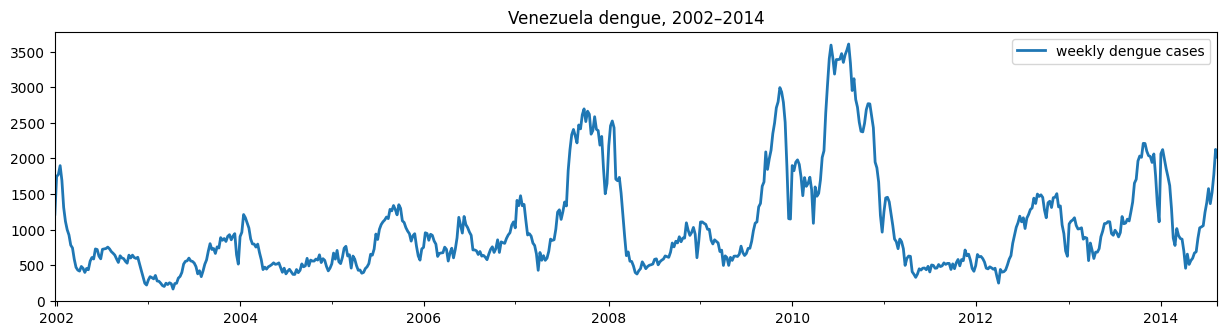

In [8]:
start = pd.to_datetime(f"{raw.Year.iloc[0]}-W{raw.Week.iloc[0]:02d}-1", format="%G-W%V-%u")
df = raw.assign(date=pd.date_range(start, periods=len(raw), freq=CFG["FREQ"]))
series = TimeSeries.from_dataframe(df, time_col="date", value_cols="Cases", freq=CFG["FREQ"]).astype(np.float32)
print("TimeSeries values shape (time, components, samples):", series.all_values().shape)

fig, ax = plt.subplots(figsize=(15, 3.5))
series.plot(ax=ax, label="weekly dengue cases"); ax.set_title("Venezuela dengue, 2002–2014"); ax.set_xlabel(""); plt.show()

In [9]:
print(series)
print("Values shape (time, components, samples):", series.all_values().shape)
print("Frequency:", series.freq_str, "| start:", series.start_time().date(), "| end:", series.end_time().date())

             Cases
date              
2001-12-31  1215.0
2002-01-07  1744.0
2002-01-14  1774.0
2002-01-21  1898.0
2002-01-28  1689.0
...            ...
2014-07-21  1364.0
2014-07-28  1520.0
2014-08-04  1770.0
2014-08-11  2126.0
2014-08-18  2020.0

shape: (660, 1, 1), freq: W-MON, size: 2.58 KB
Values shape (time, components, samples): (660, 1, 1)
Frequency: W-MON | start: 2001-12-31 | end: 2014-08-18


## Part 4 - Train, Validation, Test Split

We follow the same temporal split per horizon as the paper:

| Horizon | Train | Validation | Test |
|---------|-------|------------|------|
| 4 weeks | 647 weeks (to 19 May 2014) | 9 weeks (26 May – 21 Jul 2014) | 4 weeks (28 Jul – 18 Aug 2014) |
| 9 weeks | 638 weeks | 13 weeks (24 Mar – 16 Jun 2014) | 9 weeks (23 Jun – 18 Aug 2014) |
| 13 weeks | 621 weeks | 26 weeks (25 Nov 2013 – 19 May 2014) | 13 weeks (26 May – 18 Aug 2014) |

1. **Test** = the last **H** weeks of the series. Each horizon has its own test window.
2. **Validation** = the **V** weeks immediately before the test window. Used **only** to score Optuna trials.
3. **Train** = everything before that.
4. **Tuning (Part 7):** the scaler is fitted on **train**; each trial's model is trained on **train** and forecasts every rolling origin inside the validation window (V − H + 1 origins: 6, 5, 14). The validation weeks act as *inputs* for later origins but are never trained on.
5. **Final model (Part 8):** retrain on **train + validation** with the best settings (scaler refitted on train + validation), forecast the test window **once** from the last pre-test week; all H steps come from one forward pass.

Each horizon is a separate experiment: the H = 4 training data contain weeks that are test weeks for H = 13, which is fine because nothing is shared between horizons (separate studies, separate models).

,H (test weeks),V (validation weeks),train weeks,train period,validation period,test period,training windows (tuning),training windows (final),validation origins
short,4,9,647,2001-12-31 → 2014-05-19,2014-05-26 → 2014-07-21,2014-07-28 → 2014-08-18,592,601,6
medium,9,13,638,2001-12-31 → 2014-03-17,2014-03-24 → 2014-06-16,2014-06-23 → 2014-08-18,578,591,5
long,13,26,621,2001-12-31 → 2013-11-18,2013-11-25 → 2014-05-19,2014-05-26 → 2014-08-18,557,583,14


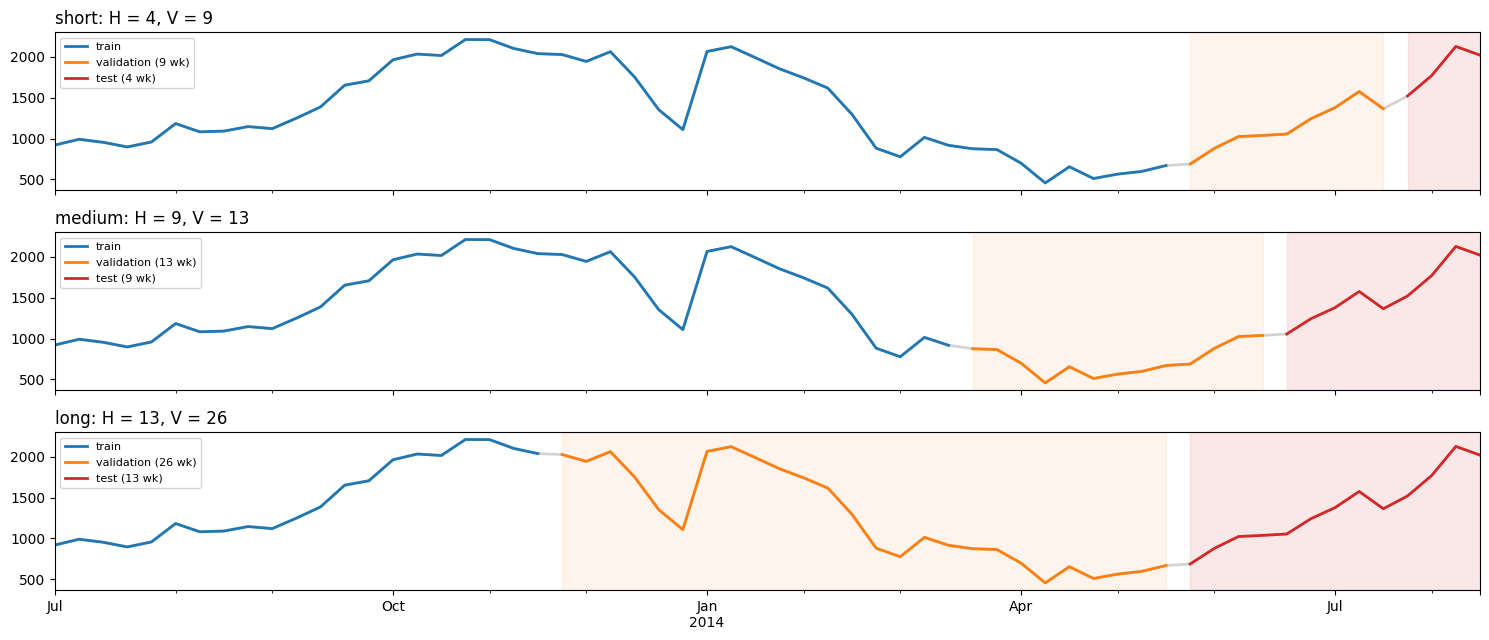

In [10]:
P = CFG["LOOKBACK"]
SPLITS = {}
for hname, hv in CFG["HORIZONS"].items():
    H, V = hv["H"], hv["V"]
    n_train = len(series) - H - V #training set length is whatever is left after removing the last H weeks (test) and the V weeks before them (validation)
    sp = dict(H=H, V=V, 
              n_train=n_train,
              train=series[:n_train],             # weeks 0 … 620
              val=series[n_train:n_train + V],    # weeks 621 … 646  (26 weeks)
              train_val=series[:n_train + V],     # weeks 0 … 646  (used for the final model)
              test=series[-H:])                   # weeks 647 … 659 (last 13 weeks)
    sp["n_train_windows"] = n_train - P - H + 1               # windows used to fit during tuning
    sp["n_final_windows"] = n_train + V - P - H + 1           # windows used to fit the final model
    sp["n_val_origins"] = V - H + 1                           # forecasts the trained model makes during validation
    SPLITS[hname] = sp

split_table = pd.DataFrame({h: {
    "H (test weeks)": s["H"], "V (validation weeks)": s["V"], "train weeks": s["n_train"],
    "train period": f"{s['train'].start_time().date()} → {s['train'].end_time().date()}",
    "validation period": f"{s['val'].start_time().date()} → {s['val'].end_time().date()}",
    "test period": f"{s['test'].start_time().date()} → {s['test'].end_time().date()}",
    "training windows (tuning)": s["n_train_windows"], "training windows (final)": s["n_final_windows"],
    "validation origins": s["n_val_origins"]} for h, s in SPLITS.items()}).T
display(split_table)

# Picture of the last 60 weeks for each horizon
fig, axes = plt.subplots(3, 1, figsize=(15, 6.5), sharex=True)
tail = series[-60:]
for ax, (hname, s) in zip(axes, SPLITS.items()):
    tail.plot(ax=ax, color="lightgray", label="_")
    s["train"].slice_intersect(tail).plot(ax=ax, label="train", color="tab:blue")
    s["val"].plot(ax=ax, label=f"validation ({s['V']} wk)", color="tab:orange")
    s["test"].plot(ax=ax, label=f"test ({s['H']} wk)", color="tab:red")
    ax.axvspan(s["val"].start_time(), s["val"].end_time(), color="tab:orange", alpha=0.08)
    ax.axvspan(s["test"].start_time(), s["test"].end_time(), color="tab:red", alpha=0.10)
    ax.set_title(f"{hname}: H = {s['H']}, V = {s['V']}", loc="left"); ax.set_xlabel(""); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# Leakage checks: the test window is disjoint from, and strictly after, everything used for fitting or tuning
for hname, sp in SPLITS.items():
    test_start = len(series) - sp["H"]
    assert sp["n_train"] + sp["V"] == test_start, hname
    assert len(sp["train_val"]) == test_start and len(sp["test"]) == sp["H"], hname
    assert sp["train"].end_time() < sp["val"].start_time() <= sp["val"].end_time() < sp["test"].start_time(), hname
    assert sp["train_val"].end_time() < sp["test"].start_time(), hname
    assert sp["n_val_origins"] >= 1, hname
print("OK  train < validation < test for every horizon; train_val ends the week before the test window")

OK  train < validation < test for every horizon; train_val ends the week before the test window


## Part 4b — Input and output tensor shapes

What the package expects (from `enblock_rnn_model.py` / `base_engression.py`), with B = batch size, p = `input_chunk_length`, q = `output_chunk_length`, M = `num_samples`, S = prediction samples:

| Stage | Expected by the package | Ours (p = 52, B = 32, M = 2, S = 100) |
|---|---|---|
| Input to `fit` / `predict` | `darts.TimeSeries`, values `(T, C, 1)` | `(T, 1, 1)`, T = training length |
| One training input window (`past_target`) | `(B, p, C)` | `(32, 26, 1)` |
| One training target (`future_target`) | `(B, q, C)` | `(32, H, 1)` |
| Window repeated M times (training) | `(M·B, p, C)` | `(64, 26, 1)` |
| Noise η added to the window | same as input | `(64, 26, 1)` |
| LSTM output, all steps | `(M·B, p, hidden)` | `(64, 26, hidden)` |
| Final hidden state `h_n[-1]` (fixed head) | `(M·B, hidden)` | `(64, hidden)`: has read all p weeks |
| Dense head output | `(M·B, q·C)` → reshaped `(M·B, q, C, 1)` | `(64, H)` → `(64, H, 1, 1)` |
| Samples passed to the energy score | `(M, B, q, C)` | `(2, 32, H, 1)` |
| `predict(n=q, num_samples=S)` result | `TimeSeries`, values `(q, C, S)` | `(H, 1, 100)` |

The last training batch of an epoch can be smaller than 32. Below, forward hooks record the shapes that actually flow through the network for each horizon (1 epoch of training plus one prediction), so you can see these numbers for real.

In [12]:
def trace_shapes(H, S=CFG["N_PRED_SAMPLES"]):
    # Records the shape of every tensor of interest the first time it appears in each phase
    from engressionts.noise import GaussianNoise, UniformNoise
    sp = next(s for s in SPLITS.values() if s["H"] == H)
    tr = make_scaler().fit_transform(sp["train"])
    m = EnBlockRNNModel(input_chunk_length=P, output_chunk_length=H, model=rnn_module("engression"), hidden_dim=16,
                        num_samples=CFG["M_TRAIN"], n_epochs=1, batch_size=CFG["BATCH_SIZE"], random_state=0,
                        pl_trainer_kwargs=dict(accelerator=ACCELERATOR, devices=1, enable_progress_bar=False,
                                               enable_model_summary=False, logger=False))
    rows, seen, phase = [], set(), {"now": "train"}
    def add(tag, shape):
        if (phase["now"], tag) not in seen:
            seen.add((phase["now"], tag)); rows.append((phase["now"], tag, tuple(shape)))
    def global_hook(mod, inp, out):
        if isinstance(mod, (GaussianNoise, UniformNoise)):
            add("1. input window x (before noise)", inp[0].shape); add("2. noisy window x + eta", out.shape)
        elif isinstance(mod, torch.nn.LSTM):
            add("3. LSTM output, all p steps", out[0].shape)
            add("3b. final hidden state h_n[-1] (fed to the head)", out[1][0][-1].shape)
        elif isinstance(mod, torch.nn.Sequential) and len(mod) and isinstance(mod[0], torch.nn.Linear):
            add("4. dense head output (H * C values per window)", out.shape)
    orig_es = eng_base.energy_score_loss
    def es_spy(samples, target):                       # wraps the loss to record what it receives
        add("5. energy score: samples (M, B, q, C)", samples.shape); add("6. energy score: target (B, q, C)", target.shape)
        return orig_es(samples, target)
    handle = torch.nn.modules.module.register_module_forward_hook(global_hook)
    eng_base.energy_score_loss = es_spy
    try:
        m.fit(tr)
        phase["now"] = "predict"
        pred = m.predict(n=H, series=tr, num_samples=S, random_state=0)
        add(f"7. predict(n={H}, num_samples={S}) -> TimeSeries values (q, C, S)", pred.all_values().shape)
    finally:
        handle.remove(); eng_base.energy_score_loss = orig_es
    return pd.DataFrame(rows, columns=["phase", "tensor", f"shape (H={H})"])

for hname, s in SPLITS.items():
    print(f"\n=== {hname}: H = {s['H']}, p = {P} ===")
    display(trace_shapes(s["H"]))


=== short: H = 4, p = 52 ===


,phase,tensor,shape (H=4)
0,train,1. input window x (before noise),"(64, 52, 1)"
1,train,2. noisy window x + eta,"(64, 52, 1)"
2,train,"3. LSTM output, all p steps","(64, 52, 16)"
3,train,3b. final hidden state h_n[-1] (fed to the head),"(64, 16)"
4,train,4. dense head output (H * C values per window),"(64, 4)"
5,train,"5. energy score: samples (M, B, q, C)","(2, 32, 4, 1)"
6,train,"6. energy score: target (B, q, C)","(32, 4, 1)"
7,predict,1. input window x (before noise),"(32, 52, 1)"
8,predict,2. noisy window x + eta,"(32, 52, 1)"
9,predict,"3. LSTM output, all p steps","(32, 52, 16)"



=== medium: H = 9, p = 52 ===


,phase,tensor,shape (H=9)
0,train,1. input window x (before noise),"(64, 52, 1)"
1,train,2. noisy window x + eta,"(64, 52, 1)"
2,train,"3. LSTM output, all p steps","(64, 52, 16)"
3,train,3b. final hidden state h_n[-1] (fed to the head),"(64, 16)"
4,train,4. dense head output (H * C values per window),"(64, 9)"
5,train,"5. energy score: samples (M, B, q, C)","(2, 32, 9, 1)"
6,train,"6. energy score: target (B, q, C)","(32, 9, 1)"
7,predict,1. input window x (before noise),"(32, 52, 1)"
8,predict,2. noisy window x + eta,"(32, 52, 1)"
9,predict,"3. LSTM output, all p steps","(32, 52, 16)"



=== long: H = 13, p = 52 ===


,phase,tensor,shape (H=13)
0,train,1. input window x (before noise),"(64, 52, 1)"
1,train,2. noisy window x + eta,"(64, 52, 1)"
2,train,"3. LSTM output, all p steps","(64, 52, 16)"
3,train,3b. final hidden state h_n[-1] (fed to the head),"(64, 16)"
4,train,4. dense head output (H * C values per window),"(64, 13)"
5,train,"5. energy score: samples (M, B, q, C)","(2, 32, 13, 1)"
6,train,"6. energy score: target (B, q, C)","(32, 13, 1)"
7,predict,1. input window x (before noise),"(32, 52, 1)"
8,predict,2. noisy window x + eta,"(32, 52, 1)"
9,predict,"3. LSTM output, all p steps","(32, 52, 16)"


**Reading the prediction rows.** For `predict(num_samples=S)`, Darts repeats the history window S times and runs the copies through the network in batches of `batch_size`. With S = 100 and `batch_size=32` the noise layer sees four batches, (32, 26, 1) × 3 and (4, 26, 1); the trace above shows the first one. Each copy gets its own noise draw, and the 100 outputs are reassembled into the `(H, 1, 100)` TimeSeries.

## Part 5 — M vs. the number of prediction samples

Both are "numbers of samples", but they act at different stages:

| | **M** (`num_samples` in the constructor) | **S** (`num_samples` in `predict`) |
|---|---|---|
| When | Training, inside every gradient step | After training, when forecasting |
| What it is | Noisy copies of each training window used to estimate the energy score | Trajectories drawn to form the forecast ensemble |
| Effect | M = 2 is the smallest value that gives the energy score its spread term; larger M gives a less noisy loss estimate | Larger S gives more stable medians, quantiles, CRPS |
| Cost | Training time and memory grow with M (the batch is M times larger; the pairwise term grows with M²) | Almost free: 100 trajectories take a few hundredths of a second |
| Paper value | M = 2 | S = 100, repeated 50 times |
| Package default | 20 | — (you choose) |

**Important: in this package M also changes the loss itself.** The energy score (paper Eq. 3) divides the pairwise term by 2M(M − 1), skipping each sample paired with itself. `engressionts` (and the `stengression` code) instead average over all M × M pairs, *including the M zero diagonal pairs*, so the spread term is multiplied by (M − 1)/M. With M = 2 it is **halved**; with M = 20 (package default) it is 5% smaller. A loss with a weakened spread term is no longer a proper scoring rule: for a Gaussian forecast it is minimised at about 0.38 × the true sd when M = 2, i.e. it rewards over-confident intervals. **This notebook deliberately trains with the package estimator only (`ES_LOSS="package"`)**, so results are comparable with anyone using engressionts as shipped; keep the bias above in mind when reading interval widths and coverage.

**How to choose.** Keep **M = 2** for comparability with the paper; the energy score with M = 2 is already an unbiased estimate of the proper scoring rule, and the extra noise in the loss averages out over epochs. Consider M = 5–10 only if training curves are very noisy. Keep **S = 100** with 50 repeats to match the paper. Because prediction is cheap, also check that conclusions do not change with S = 500 or 1000: the 2.5% and 97.5% quantiles of 100 samples rest on only 2–3 extreme draws, so interval endpoints and coverage are the quantities most sensitive to S. The cell below shows that directly once a model is trained (it runs after Part 10).

## Part 6 — Shared helpers

* `build_model` creates the engression model or the plain-LSTM benchmark with identical settings and the forecast head chosen by `CFG["HEAD"]`.
* `fit_package_es` trains a model and first **asserts that the loss the package will call is the package's own `energy_score_loss`**, so no other estimator can slip in (Part 4b temporarily wraps it and restores it).
* `sample_forecast` returns samples in case units, shape `(H, 1, S)`, clipped at 0 **after** inverse scaling.
* `score` computes all metrics with `engressionts.metrics` (median point forecast, α = 0.05).

In [13]:
def trainer_kwargs():
    return dict(accelerator=ACCELERATOR, devices=1, enable_progress_bar=False,
                enable_model_summary=False, logger=False)

def build_model(kind, H, params, seed, n_epochs=None):
    common = dict(input_chunk_length=P, output_chunk_length=H, model=rnn_module(kind),
                  hidden_dim=int(params["hidden_dim"]), n_rnn_layers=int(params["n_rnn_layers"]),
                  dropout=float(params.get("dropout", 0.0)) if int(params["n_rnn_layers"]) > 1 else 0.0,
                  n_epochs=n_epochs or CFG["N_EPOCHS"], batch_size=CFG["BATCH_SIZE"],
                  optimizer_kwargs={"lr": float(params["lr"])}, random_state=seed,
                  pl_trainer_kwargs=trainer_kwargs())
    if kind == "engression":
        return EnBlockRNNModel(**common, noise_type=params["noise_type"],
                               noise_std=float(params["noise_std"]),
                               num_samples=CFG["M_TRAIN"])
    if kind == "lstm":                                   # deterministic benchmark, MSE loss
        return BlockRNNModel(**common)
    raise ValueError(kind)

_PACKAGE_ES = eng_base.energy_score_loss               # engressionts' own estimator, captured at import time
assert CFG["ES_LOSS"] == "package"

def fit_package_es(model, series_sc):
    # Train with the engressionts package energy score (and nothing else)
    assert eng_base.energy_score_loss is _PACKAGE_ES, "energy_score_loss has been replaced; restart the kernel"
    model.fit(series_sc, verbose=False)
    return model

def sample_forecast(model, histories_sc, H, scaler, n_samples, seed):
    # histories_sc: one scaled TimeSeries or a list. Returns list of arrays (H, 1, S) in case units.
    single = isinstance(histories_sc, TimeSeries)
    preds = model.predict(n=H, series=histories_sc, num_samples=n_samples, random_state=seed)
    preds = [preds] if single else preds
    return [np.clip(scaler.inverse_transform(p).all_values(), 0, None) for p in preds]

def score(y_true_ts, samples, y_train_ts, alpha=CFG["ALPHA"]):
    y, yt = y_true_ts.values(), y_train_ts.values()
    point = dict(MAE=M.mae(y, samples, point_method="median"),
                 RMSE=M.rmse(y, samples, point_method="median"),
                 SMAPE=M.smape(y, samples, point_method="median"),
                 MASE=M.mase(y, samples, yt, point_method="median"),
                 RMSSE=M.rmsse(y, samples, yt, point_method="median"))
    if samples.shape[-1] == 1:                           # point forecast: CRPS reduces to MAE, no interval
        prob = dict(CRPS=point["MAE"], Coverage95=np.nan, Width95=np.nan, Winkler95=np.nan,
                    Pinball80=M.pinball_loss(y, samples, 0.8), Pinball95=M.pinball_loss(y, samples, 0.95))
    else:
        prob = dict(CRPS=M.crps(y, samples),
                    Coverage95=M.empirical_coverage(y, samples, alpha=alpha),
                    Width95=M.mpiw(samples, alpha=alpha),
                    Winkler95=M.winkler_score(y, samples, alpha=alpha),
                    Pinball80=M.pinball_loss(y, samples, 0.8), Pinball95=M.pinball_loss(y, samples, 0.95))
    return {k: float(np.asarray(v)) for k, v in {**point, **prob}.items()}

## Part 7 — Collect and merge the three tuning studies

The three tuning runs (`enblockrnn-tune.ipynb`, one per horizon) each saved an Optuna study in its own `.db` file. This part:

1. searches `TUNING_INPUTS` (by default `/kaggle/input` and the working folder) for `.db` files, copying each to a scratch folder first because Kaggle inputs are read-only;
2. for each horizon, picks the study `enblockrnn_<horizon>_H<H>` with the most finished trials among those **run with the same settings as this notebook** (`tuning_fingerprint`: lookback, head, loss, M, epochs, batch size, tuning seeds, search space, run mode, …). A study from the earlier single-notebook version has no stored settings; it is accepted with a note;
3. checks that each horizon has at least `N_TRIALS` finished trials (`REQUIRE_FULL_TUNING`);
4. copies the three studies into one file, `optuna_all_horizons.db` in `OUT_DIR`, and loads the best settings into `BEST`.

Nothing here retrains or rescores anything; the tuning results are used exactly as the tuning runs left them.

In [14]:
import glob, shutil

def params_from_trial(t):
    # Full parameter dict from a finished trial (dropout is only sampled when n_rnn_layers > 1)
    return {**t.params, "dropout": t.params.get("dropout", 0.0)}

def n_finished(st):
    return sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in st.trials)

merged_path = CFG["OPTUNA_STORAGE"].replace("sqlite:///", "")
staging = os.path.join(CFG["OUT_DIR"], "_staging")
shutil.rmtree(staging, ignore_errors=True); os.makedirs(staging)
skip = {os.path.abspath(merged_path), os.path.abspath(staging)}
db_files = sorted({os.path.abspath(p) for root in CFG["TUNING_INPUTS"] if os.path.isdir(root)
                   for p in glob.glob(os.path.join(root, "**", "*.db"), recursive=True)})
db_files = [p for p in db_files if not any(p == s or p.startswith(s + os.sep) for s in skip)]
print(f"Found {len(db_files)} .db file(s):", *db_files, sep="\n  ")

found = {}                       # study name -> list of candidates
for i, path in enumerate(db_files):
    local = os.path.join(staging, f"{i}.db"); shutil.copy(path, local)
    url = f"sqlite:///{local}"
    try:
        names = optuna.study.get_all_study_names(url)
    except Exception as e:
        print(f"  skipped {path}: {e.__class__.__name__}"); continue
    for name in names:
        st = optuna.load_study(study_name=name, storage=url)
        found.setdefault(name, []).append(dict(path=path, url=url, n=n_finished(st),
                                               fp=st.user_attrs.get("tuning_fingerprint")))

if os.path.exists(merged_path):
    os.remove(merged_path)                       # rebuild the merged file from the tuning outputs every time
STUDIES, BEST, sources, problems = {}, {}, [], []
for hname, sp in SPLITS.items():
    name, fp = f"enblockrnn_{hname}_H{sp['H']}", tuning_fingerprint(hname)
    cands = found.get(name, [])
    ok = [c for c in cands if c["fp"] in (None, fp)]
    rejected = [f"{c['path']} differs in {sorted(k for k in set(fp) | set(c['fp']) if fp.get(k) != c['fp'].get(k))}"
                for c in cands if c not in ok]
    note = ("; also found with different settings: " + "; ".join(rejected)) if rejected else ""
    if not ok:
        problems.append(f"{hname}: no study '{name}' with matching settings" + (note if cands else " (not found)"))
        continue
    best_c = max(ok, key=lambda c: (c["fp"] is not None, c["n"]))   # prefer studies that recorded their settings
    if best_c["n"] < CFG["N_TRIALS"] and CFG["REQUIRE_FULL_TUNING"]:
        problems.append(f"{hname}: only {best_c['n']} of {CFG['N_TRIALS']} trials finished in {best_c['path']}{note}")
        continue
    optuna.copy_study(from_study_name=name, from_storage=best_c["url"], to_storage=CFG["OPTUNA_STORAGE"])
    study = optuna.load_study(study_name=name, storage=CFG["OPTUNA_STORAGE"])
    STUDIES[hname], BEST[hname] = study, params_from_trial(study.best_trial)
    sources.append(dict(horizon=hname, H=sp["H"], file=best_c["path"], finished=best_c["n"],
                        complete=sum(t.state == TrialState.COMPLETE for t in study.trials),
                        pruned=sum(t.state == TrialState.PRUNED for t in study.trials),
                        best_val_CRPS=study.best_value, best_trial=study.best_trial.number,
                        settings_checked="yes" if best_c["fp"] is not None else "not recorded (older notebook)"))
shutil.rmtree(staging, ignore_errors=True)

if sources:
    display(pd.DataFrame(sources).set_index("horizon"))
if problems:
    raise RuntimeError("Tuning results incomplete:\n  " + "\n  ".join(problems)
                       + "\nAttach the tuning notebooks' outputs (Add Input) or finish their runs.")
print(f"Merged {len(STUDIES)} studies into {merged_path}")

Found 3 .db file(s):
  /kaggle/input/datasets/nilashamajumdar1/optuna-long/optuna_long.db
  /kaggle/input/datasets/nilashamajumdar1/optuna-medium/optuna_medium.db
  /kaggle/input/datasets/nilashamajumdar1/optuna-short/optuna_short.db


,H,file,finished,complete,pruned,best_val_CRPS,best_trial,settings_checked
horizon,,,,,,,,
short,4,/kaggle/input/datasets/nilashamajumdar1/optuna...,100,54,46,142.710194,88,yes
medium,9,/kaggle/input/datasets/nilashamajumdar1/optuna...,100,52,48,85.259610,79,yes
long,13,/kaggle/input/datasets/nilashamajumdar1/optuna...,100,64,36,235.464005,91,yes


Merged 3 studies into outputs_enblockrnn_final/optuna_all_horizons.db


### Tuning results

The table compares the **best trial** with **trial 0 (the untuned defaults)** on the validation window. Both are means over the same 3 seeds and all rolling origins. The figures show the search history (each dot is a finished trial; the line is the best so far) and which settings mattered most.

Validation results: untuned defaults vs. best Optuna trial (CRPS in cases/week, lower is better)


H  number  val CRPS  sd over seeds  \
horizon trial                                                    
short   untuned (trial 0)   4       0  340.2146        58.1294   
        best                4      88  142.7102        40.2797   
medium  untuned (trial 0)   9       0  174.8156        15.1433   
        best                9      79   85.2596         2.1654   
long    untuned (trial 0)  13       0  448.0923        15.1402   
        best               13      91  235.4640         3.8372   

                           val coverage95  val width95  hidden_dim  \
horizon trial                                                        
short   untuned (trial 0)          0.4583     648.7913          32   
        best                       0.2778     193.7665          79   
medium  untuned (trial 0)          0.8741    1355.1264          32   
        best                       0.6667     309.2911          43   
long    untuned (trial 0)          0.5934    1755.8279          32   
        best                       0.8077    1218.2738          76   

                           n_rnn_layers      lr noise_type  noise_std  \
horizon trial                                                           
short   untuned (trial 0)             1  0.0010   gaussian     1.0000   
        best                          3  0.0116    uniform     0.1029   
medium  untuned (trial 0)             1  0.0010   gaussian     1.0000   
        best                          3  0.0001    uniform     0.7165   
long    untuned (trial 0)             1  0.0010   gaussian     1.0000   
        best                          1  0.0001   gaussian     1.0774   

                           log_transform  dropout  
horizon trial                                      
short   untuned (trial 0)           True   0.0000  
        best                       False   0.0741  
medium  untuned (trial 0)           True   0.0000  
        best                        True   0.4579  
long    untuned (trial 0)           True   0.0000  
        best                       False   0.0000

Best hyper-parameters per horizon (used for the final model):


,hidden_dim,n_rnn_layers,lr,noise_type,noise_std,log_transform,dropout
short,79,3,0.011623,uniform,0.102865,False,0.074149
medium,43,3,0.000088,uniform,0.716499,True,0.45786
long,76,1,0.000093,gaussian,1.077418,False,0.0


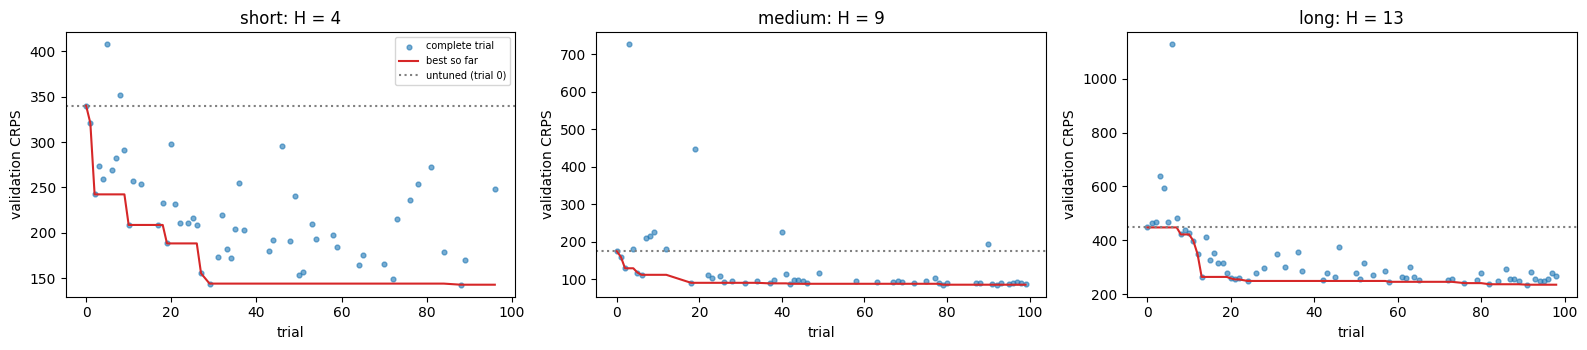

Hyper-parameter importance (fANOVA, share of validation-CRPS variance explained):


,short,medium,long
lr,0.631,0.181,0.564
n_rnn_layers,0.151,0.044,0.134
dropout,0.095,0.031,0.000
noise_std,0.076,0.680,0.214
hidden_dim,0.044,0.064,0.084
noise_type,0.002,0.000,0.001
log_transform,0.001,0.000,0.003


In [15]:
rows = []
for hname, study in STUDIES.items():
    t0_ = next(t for t in study.trials if t.number == 0)
    bt = study.best_trial
    for label, t in [("untuned (trial 0)", t0_), ("best", bt)]:
        rows.append({"horizon": hname, "H": SPLITS[hname]["H"], "trial": label, "number": t.number,
                     "val CRPS": t.value, "sd over seeds": t.user_attrs.get("crps_sd_seeds"),
                     "val coverage95": t.user_attrs.get("coverage95"), "val width95": t.user_attrs.get("width95"),
                     **params_from_trial(t)})
tuning_summary = pd.DataFrame(rows).set_index(["horizon", "trial"])
print("Validation results: untuned defaults vs. best Optuna trial (CRPS in cases/week, lower is better)")
display(tuning_summary.round(4))

print("Best hyper-parameters per horizon (used for the final model):")
display(pd.DataFrame(BEST).T)

fig, axes = plt.subplots(1, len(STUDIES), figsize=(16, 3.6))
for ax, (hname, study) in zip(np.atleast_1d(axes), STUDIES.items()):
    done = [t for t in study.trials if t.state == TrialState.COMPLETE]
    x = [t.number for t in done]; y = [t.value for t in done]
    ax.scatter(x, y, s=12, alpha=0.6, label="complete trial")
    ax.plot(x, np.minimum.accumulate(y), color="tab:red", lw=1.5, label="best so far")
    ax.axhline(next(t for t in study.trials if t.number == 0).value, color="gray", ls=":", label="untuned (trial 0)")
    ax.set_title(f"{hname}: H = {SPLITS[hname]['H']}"); ax.set_xlabel("trial"); ax.set_ylabel("validation CRPS")
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_optuna_history.png", dpi=150); plt.show()

imp_rows = {}
for hname, study in STUDIES.items():
    try:
        imp_rows[hname] = optuna.importance.get_param_importances(study)
    except Exception as e:                                # needs enough complete trials
        print(f"{hname}: importances not available ({e.__class__.__name__}: {e})")
if imp_rows:
    print("Hyper-parameter importance (fANOVA, share of validation-CRPS variance explained):")
    display(pd.DataFrame(imp_rows).round(3))

## Part 8 — Final training on train + validation with the best settings

For each horizon and each of the 5 final seeds: fit the transform (with the **tuned** log choice) on **train + validation**, build EnBlockRNN with `BEST[horizon]`, and train for `N_EPOCHS` epochs with the **package** energy score. The plain-LSTM benchmark keeps its fixed defaults (`LSTM_PARAMS`, not tuned) and is trained the same way with MSE.

`LossHistory` stores the per-epoch training loss for Part 9. The test window is still untouched; it is first used in Part 10.

In [16]:
class LossHistory(pl.Callback):
    # Collects the per-epoch training loss: "energy_score_train_loss" (engression) or "train_loss" (plain LSTM, MSE)
    def __init__(self): self.train_loss = []
    def on_train_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        v = m.get("energy_score_train_loss_epoch", m.get("train_loss"))
        if v is not None: self.train_loss.append(float(v))

missing = [h for h in SPLITS if h not in BEST]
assert not missing, f"Horizons not tuned yet: {missing}. Tune them in Part 7 (TUNE_HORIZONS) before the final run."

KINDS = ["engression"] + (["lstm"] if CFG["RUN_BENCHMARKS"] else [])
FINAL = {}          # (kind, hname, seed) -> dict(model, scaler, history_sc, train_seconds, loss_curve, params)
for kind in KINDS:
    for hname, sp in SPLITS.items():
        params = BEST[hname] if kind == "engression" else LSTM_PARAMS
        for seed in CFG["SEEDS"]:
            scaler = make_scaler(params["log_transform"])
            tv_sc = scaler.fit_transform(sp["train_val"])          # transform fitted on train + validation only
            t0 = time.time()
            model = build_model(kind, sp["H"], params, seed=seed)
            hist = LossHistory(); model.trainer_params["callbacks"] = [hist]
            fit_package_es(model, tv_sc)                           # engression: package ES; LSTM: MSE
            FINAL[(kind, hname, seed)] = dict(model=model, scaler=scaler, history_sc=tv_sc, params=params,
                                              train_seconds=time.time() - t0, loss_curve=hist.train_loss)
        secs = np.mean([FINAL[(kind, hname, s)]["train_seconds"] for s in CFG["SEEDS"]])
        print(f"{kind:10s} {hname:6s}: trained {len(CFG['SEEDS'])} seeds, {CFG['N_EPOCHS']} epochs each ({secs:.0f}s per seed)")

engression short : trained 5 seeds, 100 epochs each (13s per seed)
engression medium: trained 5 seeds, 100 epochs each (13s per seed)
engression long  : trained 5 seeds, 100 epochs each (11s per seed)
lstm       short : trained 5 seeds, 100 epochs each (8s per seed)
lstm       medium: trained 5 seeds, 100 epochs each (8s per seed)
lstm       long  : trained 5 seeds, 100 epochs each (9s per seed)


## Part 9 — Training loss curves: the fall in energy score

One line per training seed. Values are in **standardised units** (log units if the tuned setting uses the log transform; the series has mean 0 and sd 1 after the transform), so a loss of 0.5 means "off by about half a standard deviation". For reference, this part also prints what simple forecasts would score on the same training windows:

* **always predict the average, no spread**: what an untrained network scores, so the curve should **start near this line**;
* **repeat the last observed week**: a strong baseline for a smooth weekly series; a well-trained model should end **below** it.

**How to read the curves.** Healthy: falls quickly, then flattens before the last epoch. Still falling at the end: undertrained (more epochs or a higher learning rate). Flat from the start: learning rate too low. Some jitter is normal: with M = 2 each batch's loss rests on two noisy copies. The curve shows that training works; forecast quality is judged on held-out weeks (Parts 7 and 12).

**Why the paper's numbers are bigger.** The paper's code takes one norm over the **whole forecast path**, e.g. 30 days × 11 provinces = 330 values for Belgium, so its loss is roughly √330 ≈ 18 times our per-week scale. A paper loss falling from 12 to 8 corresponds to roughly 0.66 to 0.44 per value: the same range as ours.

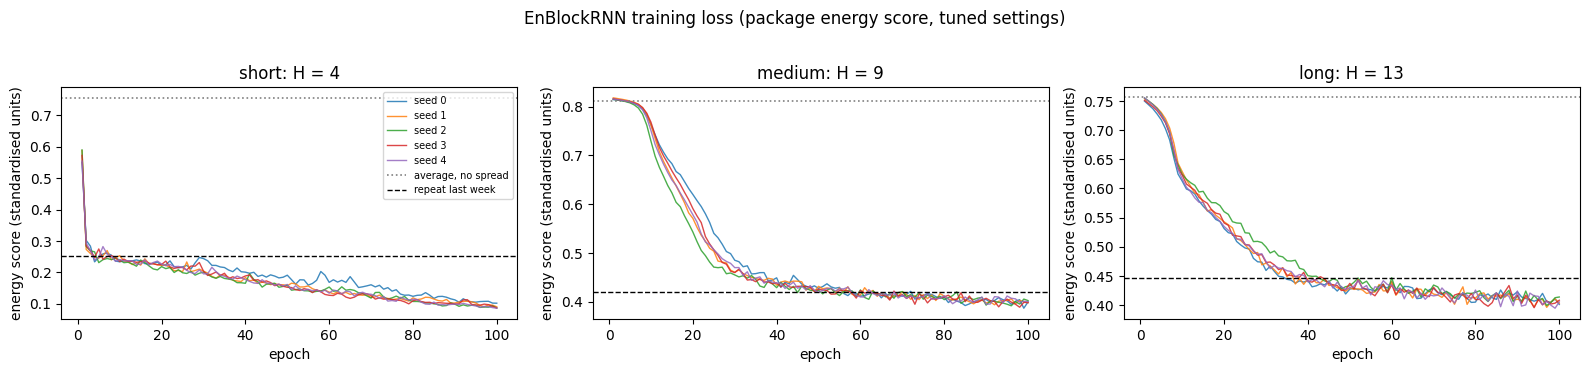

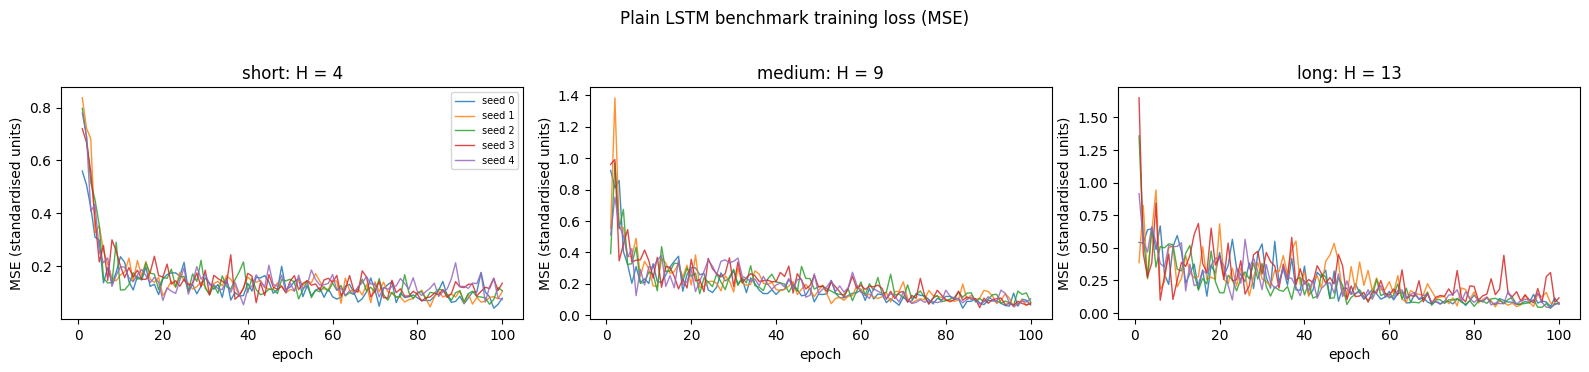

EnBlockRNN training energy score, mean over seeds:


,epoch 1,epoch 10,last epoch,fall (%),"ref: average, no spread",ref: repeat last week
horizon,,,,,,
short,0.571,0.240,0.090,84.294,0.756,0.251
medium,0.816,0.755,0.399,51.053,0.813,0.419
long,0.753,0.621,0.406,46.020,0.757,0.446


In [17]:
def reference_scores(sp, H, log_transform):
    # Scores of simple forecasts on the same training windows, in the same units as the training loss
    z = make_scaler(log_transform).fit_transform(sp["train_val"]).values()[:, 0]
    idx = range(P, len(z) - H + 1)
    Y = np.stack([z[i:i + H] for i in idx]); last = np.array([z[i - 1] for i in idx])[:, None]
    return {"average, no spread": float(np.abs(Y).mean()),
            "repeat last week": float(np.abs(np.repeat(last, H, 1) - Y).mean())}

for kind, ylabel in [("engression", "energy score (standardised units)"), ("lstm", "MSE (standardised units)")]:
    if kind not in KINDS: continue
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(16, 3.6))
    for ax, (hname, sp) in zip(axes, SPLITS.items()):
        for seed in CFG["SEEDS"]:
            c = FINAL[(kind, hname, seed)]["loss_curve"]
            ax.plot(range(1, len(c) + 1), c, lw=1, alpha=0.85, label=f"seed {seed}")
        if kind == "engression":
            ref = reference_scores(sp, sp["H"], BEST[hname]["log_transform"])
            ax.axhline(ref["average, no spread"], color="gray", ls=":", lw=1.2, label="average, no spread")
            ax.axhline(ref["repeat last week"], color="black", ls="--", lw=1, label="repeat last week")
        ax.set_title(f"{hname}: H = {sp['H']}"); ax.set_xlabel("epoch"); ax.set_ylabel(ylabel)
    axes[0].legend(fontsize=7)
    fig.suptitle("EnBlockRNN training loss (package energy score, tuned settings)" if kind == "engression"
                 else "Plain LSTM benchmark training loss (MSE)", y=1.02)
    plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_training_loss_{kind}.png", dpi=150, bbox_inches="tight"); plt.show()

rows = []
for hname, sp in SPLITS.items():
    c = np.array([FINAL[("engression", hname, s)]["loss_curve"] for s in CFG["SEEDS"]])
    ref = reference_scores(sp, sp["H"], BEST[hname]["log_transform"])
    rows.append({"horizon": hname, "epoch 1": c[:, 0].mean(), "epoch 10": c[:, min(9, c.shape[1] - 1)].mean(),
                 "last epoch": c[:, -1].mean(), "fall (%)": 100 * (1 - c[:, -1].mean() / c[:, 0].mean()),
                 "ref: average, no spread": ref["average, no spread"], "ref: repeat last week": ref["repeat last week"]})
print("EnBlockRNN training energy score, mean over seeds:")
display(pd.DataFrame(rows).set_index("horizon").round(3))

In [18]:
# Part 5 demonstration: how stable are the 95% interval endpoints for different S? (long horizon, seed 0)
# Uses only the forecast samples, not the test values.
f = FINAL[("engression", "long", CFG["SEEDS"][0])]
H = SPLITS["long"]["H"]
rows = []
for S in [20, 100, 500, 1000]:
    lo, hi = [], []
    for r in range(20):
        smp = sample_forecast(f["model"], f["history_sc"], H, f["scaler"], S, seed=1000 + r)[0]
        lo.append(np.quantile(smp, 0.025, axis=-1).mean()); hi.append(np.quantile(smp, 0.975, axis=-1).mean())
    rows.append(dict(S=S, **{"mean lower 2.5%": np.mean(lo), "sd lower": np.std(lo),
                             "mean upper 97.5%": np.mean(hi), "sd upper": np.std(hi)}))
print("Spread of interval endpoints across 20 repeated ensembles (case units):")
pd.DataFrame(rows).set_index("S").round(2)

Spread of interval endpoints across 20 repeated ensembles (case units):


,mean lower 2.5%,sd lower,mean upper 97.5%,sd upper
S,,,,
20,433.929993,37.520000,1084.770020,163.220001
100,409.859985,20.540001,1153.290039,77.910004
500,396.290009,13.100000,1173.140015,36.310001
1000,394.089996,6.830000,1194.089966,25.620001


## Part 10 — Forecasting the test window: 50 repeated ensembles per trained model

As in the paper: for each trained model, draw `N_EVAL_REPEATS` independent ensembles of `N_PRED_SAMPLES` trajectories (different noise seeds), score each against the test window, and average. With several training seeds we report two spreads:

* **sd (noise)**: within-model spread over the 50 ensembles, averaged over seeds (the paper's "mean (sd)").
* **sd (seeds)**: spread of the per-seed means across training seeds (variation due to training).

The deterministic LSTM benchmark has one forecast per seed, so only the seed spread applies.

This is the **only** place the test values are used (plus the benchmarks in Part 11, scored the same way). Nothing computed here feeds back into any setting.

In [19]:
EVAL_ROWS, SAMPLES_KEEP, PRED_TIME = [], {}, {}
for (kind, hname, seed), f in FINAL.items():
    sp = SPLITS[hname]; H = sp["H"]
    reps = CFG["N_EVAL_REPEATS"] if kind == "engression" else 1
    nS = CFG["N_PRED_SAMPLES"] if kind == "engression" else 1
    t0 = time.time()
    for r in range(reps):
        smp = sample_forecast(f["model"], f["history_sc"], H, f["scaler"], nS, seed=r)[0]
        EVAL_ROWS.append(dict(model=kind, horizon=hname, H=H, seed=seed, repeat=r, **score(sp["test"], smp, sp["train_val"])))
        if r == 0: SAMPLES_KEEP[(kind, hname, seed)] = smp
    PRED_TIME[(kind, hname, seed)] = (time.time() - t0) / reps
eval_df = pd.DataFrame(EVAL_ROWS)
print(eval_df.shape, "evaluation rows")

(765, 16) evaluation rows


## Part 11 — Benchmarks on the same splits

A small benchmark set, all fitted on train + validation and scored on the same test windows:

* **Naive** (last observed week, repeated): point forecast. Any model should beat this to be worth using.
* **Seasonal naive** (value 52 weeks earlier): point forecast.
* **AutoARIMA** and **AutoETS** (statsforecast, through Darts): probabilistic, 100 samples × 50 repeats like the engression model. Seasonal length 52; AutoETS falls back to a non-seasonal model when the season is too long for ETS.
* **LSTM** (`BlockRNNModel` with the same fixed head, MSE loss): trained in Part 8 with **fixed, untuned** defaults (hidden 32, 1 layer, lr 1e-3, log1p), same epochs and seeds. Point forecast, so CRPS = MAE. Note that EnBlockRNN is tuned and this benchmark is not; say so when comparing them.

Statistical models are fitted on case counts directly (no scaling needed).

In [20]:
def fit_stat(name, H, y):
    if name == "Naive":
        return NaiveSeasonal(K=1).fit(y)          # repeats the last observed week
    if name == "SeasonalNaive":
        return NaiveSeasonal(K=52).fit(y)
    if name == "AutoARIMA":
        return AutoARIMA(season_length=52).fit(y)
    if name == "AutoETS":
        return AutoETS(season_length=52).fit(y)

# AutoARIMA takes ~4-6 min per horizon (CPU only, a GPU does not help); skipped in quick mode
BENCH_STAT = [] if not CFG["RUN_BENCHMARKS"] else ["Naive", "SeasonalNaive", "AutoETS"] + ([] if RUN_MODE == "quick" else ["AutoARIMA"])
for name in BENCH_STAT:
    for hname, sp in SPLITS.items():
        H = sp["H"]; t0 = time.time()
        try:
            m = fit_stat(name, H, sp["train_val"])
        except Exception as e:
            print(f"{name} {hname} failed: {e}"); continue
        fit_s = time.time() - t0
        prob = m.supports_probabilistic_prediction and name not in ("Naive", "SeasonalNaive")
        reps = CFG["N_EVAL_REPEATS"] if prob else 1
        for r in range(reps):
            if prob:
                p = m.predict(H, num_samples=CFG["N_PRED_SAMPLES"], random_state=r)
            else:
                p = m.predict(H)
            smp = np.clip(p.all_values(), 0, None)
            EVAL_ROWS.append(dict(model=name, horizon=hname, H=H, seed=0, repeat=r, **score(sp["test"], smp, sp["train_val"])))
            if r == 0: SAMPLES_KEEP[(name, hname, 0)] = smp
        FINAL[(name, hname, 0)] = dict(train_seconds=fit_s)
        print(f"{name:13s} {hname:6s} done ({fit_s:.1f}s)")
eval_df = pd.DataFrame(EVAL_ROWS)

Naive         short  done (0.0s)
Naive         medium done (0.0s)
Naive         long   done (0.0s)
SeasonalNaive short  done (0.0s)
SeasonalNaive medium done (0.0s)
SeasonalNaive long   done (0.0s)
AutoETS       short  done (1.2s)
AutoETS       medium done (1.2s)
AutoETS       long   done (1.3s)
AutoARIMA     short  done (301.3s)
AutoARIMA     medium done (342.5s)
AutoARIMA     long   done (255.8s)


## Part 12 — Results

**Table 1** reports mean test metrics per model and horizon; the best value in each column within a horizon is bold. Coverage closest to 0.95 is best for coverage, but read it together with width and Winkler. **Table 2** gives the spreads. Report results honestly, including cases where a benchmark wins.

In [21]:
METRICS = ["MAE", "RMSE", "SMAPE", "MASE", "RMSSE", "CRPS", "Pinball80", "Pinball95", "Coverage95", "Width95", "Winkler95"]
LABEL = {"engression": "EnBlockRNN (LSTM, tuned)", "lstm": "LSTM (MSE, untuned)"}
eval_df["Model"] = eval_df["model"].map(LABEL).fillna(eval_df["model"])

per_seed = eval_df.groupby(["horizon", "H", "Model", "seed"])[METRICS].mean()
table1 = per_seed.groupby(["H", "Model"]).mean()
sd_seeds = per_seed.groupby(["H", "Model"]).std()
sd_noise = eval_df.groupby(["H", "Model", "seed"])[METRICS].std().groupby(["H", "Model"]).mean()

def bold_best(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    for H in df.index.get_level_values(0).unique():
        block = df.loc[H]
        for c in df.columns:
            if block[c].isna().all(): continue
            best = (block[c] - 0.95).abs().idxmin() if c == "Coverage95" else block[c].idxmin()
            styles.loc[(H, best), c] = "font-weight: bold; background-color: #e6f2ff"
    return styles

print("Table 1. Mean test metrics (case units; H in weeks)")
display(table1.round(2).style.apply(bold_best, axis=None).format("{:.2f}"))
print("Table 2a. sd across training seeds (NaN for benchmarks fitted once: statistical models are deterministic in training)"); display(sd_seeds[["MAE", "CRPS", "Coverage95", "Width95"]].round(2))
print("Table 2b. sd across the repeated ensembles (noise), averaged over seeds"); display(sd_noise[["MAE", "CRPS", "Coverage95", "Width95"]].round(2))

times = pd.DataFrame([dict(model=LABEL.get(k, k), horizon=h, seed=s, train_seconds=f["train_seconds"],
                           predict_seconds_per_ensemble=PRED_TIME.get((k, h, s), np.nan)) for (k, h, s), f in FINAL.items()])
print("Table 3. Computational time (mean over seeds), seconds")
display(times.groupby(["horizon", "model"])[["train_seconds", "predict_seconds_per_ensemble"]].mean().round(3))

Table 1. Mean test metrics (case units; H in weeks)


Table 2a. sd across training seeds (NaN for benchmarks fitted once: statistical models are deterministic in training)


MAE    CRPS  Coverage95  Width95
H  Model                                                        
4  AutoARIMA                    NaN     NaN         NaN      NaN
   AutoETS                      NaN     NaN         NaN      NaN
   EnBlockRNN (LSTM, tuned)   98.64   96.94        0.32    87.22
   LSTM (MSE, untuned)       118.09  118.09         NaN      NaN
   Naive                        NaN     NaN         NaN      NaN
   SeasonalNaive                NaN     NaN         NaN      NaN
9  AutoARIMA                    NaN     NaN         NaN      NaN
   AutoETS                      NaN     NaN         NaN      NaN
   EnBlockRNN (LSTM, tuned)   26.19   30.06        0.04    51.15
   LSTM (MSE, untuned)       205.24  205.24         NaN      NaN
   Naive                        NaN     NaN         NaN      NaN
   SeasonalNaive                NaN     NaN         NaN      NaN
13 AutoARIMA                    NaN     NaN         NaN      NaN
   AutoETS                      NaN     NaN         NaN      NaN
   EnBlockRNN (LSTM, tuned)   14.32   20.10        0.05    67.31
   LSTM (MSE, untuned)       102.09  102.09         NaN      NaN
   Naive                        NaN     NaN         NaN      NaN
   SeasonalNaive                NaN     NaN         NaN      NaN

Table 2b. sd across the repeated ensembles (noise), averaged over seeds


MAE   CRPS  Coverage95  Width95
H  Model                                                      
4  AutoARIMA                 13.63  13.37        0.15    40.16
   AutoETS                   16.94  15.16        0.12    50.19
   EnBlockRNN (LSTM, tuned)   7.44   4.91        0.04    32.09
   LSTM (MSE, untuned)         NaN    NaN         NaN      NaN
   Naive                       NaN    NaN         NaN      NaN
   SeasonalNaive               NaN    NaN         NaN      NaN
9  AutoARIMA                 15.16  10.28        0.10    28.89
   AutoETS                   13.98   9.73        0.08    26.79
   EnBlockRNN (LSTM, tuned)  20.20  18.32        0.07    43.28
   LSTM (MSE, untuned)         NaN    NaN         NaN      NaN
   Naive                       NaN    NaN         NaN      NaN
   SeasonalNaive               NaN    NaN         NaN      NaN
13 AutoARIMA                 17.26  11.72        0.06    30.33
   AutoETS                    9.10   6.98        0.06    20.39
   EnBlockRNN (LSTM, tuned)  20.24  22.24        0.09   106.58
   LSTM (MSE, untuned)         NaN    NaN         NaN      NaN
   Naive                       NaN    NaN         NaN      NaN
   SeasonalNaive               NaN    NaN         NaN      NaN

Table 3. Computational time (mean over seeds), seconds


train_seconds  predict_seconds_per_ensemble
horizon model                                                                
long    AutoARIMA                       255.766                           NaN
        AutoETS                           1.265                           NaN
        EnBlockRNN (LSTM, tuned)         10.796                         0.085
        LSTM (MSE, untuned)               8.946                         0.079
        Naive                             0.000                           NaN
        SeasonalNaive                     0.000                           NaN
medium  AutoARIMA                       342.530                           NaN
        AutoETS                           1.165                           NaN
        EnBlockRNN (LSTM, tuned)         12.706                         0.092
        LSTM (MSE, untuned)               7.934                         0.076
        Naive                             0.000                           NaN
        SeasonalNaive                     0.000                           NaN
short   AutoARIMA                       301.262                           NaN
        AutoETS                           1.216                           NaN
        EnBlockRNN (LSTM, tuned)         12.722                         0.088
        LSTM (MSE, untuned)               8.125                         0.079
        Naive                             0.000                           NaN
        SeasonalNaive                     0.000                           NaN

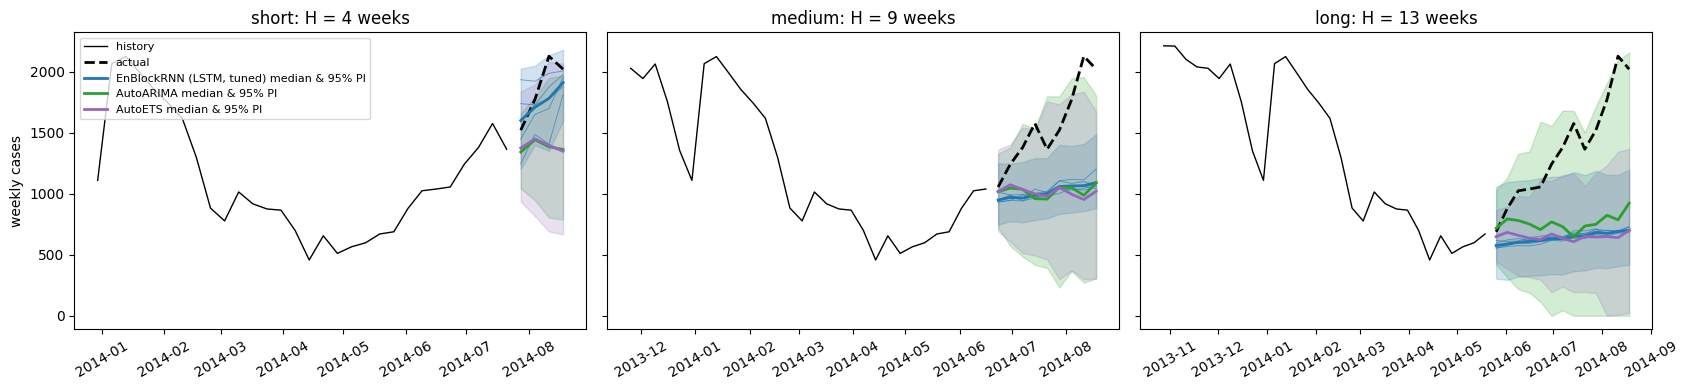

EnBlockRNN step-1 median by training seed (cases):


,last observed,actual next week,seed 0,seed 1,seed 2,seed 3,seed 4
horizon,,,,,,,
short,1364.0,1520.0,1933.0,1446.0,1245.0,1737.0,1598.0
medium,1038.0,1055.0,946.0,1014.0,930.0,952.0,933.0
long,670.0,688.0,617.0,556.0,562.0,554.0,594.0


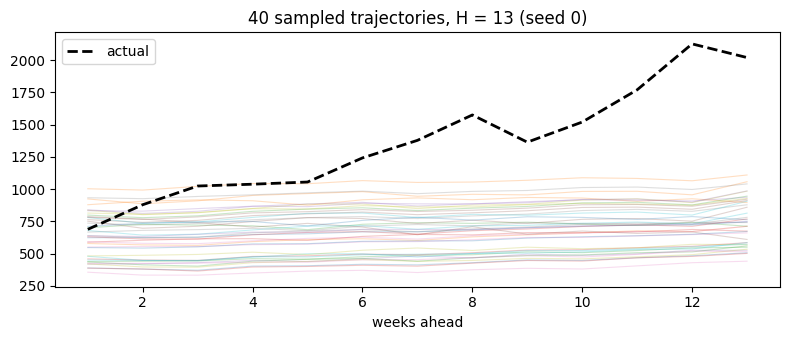

In [22]:
LABEL = {"engression": "EnBlockRNN (LSTM, tuned)", "lstm": "LSTM (MSE, untuned)"}
# Figure: test forecasts with 95% PI. Learned models: samples pooled over ALL training seeds
# (thin lines = each seed's median), so the plot matches the seed-averaged tables.
def pooled(kind, hname):
    keys = sorted(k for k in SAMPLES_KEEP if k[0] == kind and k[1] == hname)
    return np.concatenate([SAMPLES_KEEP[k][:, 0, :] for k in keys], axis=1), [SAMPLES_KEEP[k][:, 0, :] for k in keys]

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, (hname, sp) in zip(axes, SPLITS.items()):
    hist = sp["train_val"][-30:]
    ax.plot(hist.time_index, hist.values().ravel(), color="black", lw=1, label="history")
    ax.plot(sp["test"].time_index, sp["test"].values().ravel(), "k--", lw=2, label="actual")
    for kind, col in [("engression", "tab:blue"), ("AutoARIMA", "tab:green"), ("AutoETS", "tab:purple")]:
        if not any(k[0] == kind and k[1] == hname for k in SAMPLES_KEEP): continue
        s, per_seed = pooled(kind, hname)
        ax.fill_between(sp["test"].time_index, np.quantile(s, 0.025, 1), np.quantile(s, 0.975, 1), color=col, alpha=0.2)
        ax.plot(sp["test"].time_index, np.median(s, 1), color=col, lw=2, label=LABEL.get(kind, kind) + " median & 95% PI")
        if len(per_seed) > 1:
            for ps in per_seed:
                ax.plot(sp["test"].time_index, np.median(ps, 1), color=col, lw=0.7, alpha=0.6)
    ax.set_title(f"{hname}: H = {sp['H']} weeks"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("weekly cases"); axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_test_forecasts.png", dpi=150); plt.show()

# First forecast step vs the last observed week, per training seed
first = []
for hname, sp in SPLITS.items():
    row = {"horizon": hname, "last observed": float(sp["train_val"].values()[-1, 0]),
           "actual next week": float(sp["test"].values()[0, 0])}
    for k in sorted(k for k in SAMPLES_KEEP if k[0] == "engression" and k[1] == hname):
        row[f"seed {k[2]}"] = float(np.median(SAMPLES_KEEP[k][0, 0, :]))
    first.append(row)
print("EnBlockRNN step-1 median by training seed (cases):")
display(pd.DataFrame(first).set_index("horizon").round(0))

# Sampled trajectories, long horizon (seed 0)
s = SAMPLES_KEEP[("engression", "long", CFG["SEEDS"][0])][:, 0, :]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, s.shape[0] + 1), s[:, :40], alpha=0.25, lw=0.8)
ax.plot(range(1, s.shape[0] + 1), SPLITS["long"]["test"].values().ravel(), "k--", lw=2, label="actual")
ax.set_xlabel("weeks ahead"); ax.set_title("40 sampled trajectories, H = 13 (seed 0)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_trajectories_H13.png", dpi=150); plt.show()

### Validation vs. test for the tuned model

Validation CRPS is the mean over rolling origins inside the validation window (model fitted on train); test CRPS is one window per horizon (model fitted on train + validation). A test score much worse than validation usually means the test window is harder (e.g. a sharp rise), not that the tuning failed; the opposite (test much better) is common for a single easy window. Do **not** go back and re-tune because of this table.

In [23]:
vt = pd.DataFrame({hname: {"H": SPLITS[hname]["H"],
                           f"val CRPS (best trial, {len(CFG['TUNE_SEEDS'])} seeds)": STUDIES[hname].best_value,
                           "val coverage95": STUDIES[hname].best_trial.user_attrs.get("coverage95"),
                           f"test CRPS ({len(CFG['SEEDS'])} seeds x {CFG['N_EVAL_REPEATS']} ens.)": table1.loc[(SPLITS[hname]["H"], LABEL["engression"]), "CRPS"],
                           "test coverage95": table1.loc[(SPLITS[hname]["H"], LABEL["engression"]), "Coverage95"]}
                   for hname in SPLITS}).T
display(vt.round(3))

,H,"val CRPS (best trial, 3 seeds)",val coverage95,test CRPS (5 seeds x 50 ens.),test coverage95
short,4.0,142.710,0.278,164.743,0.543
medium,9.0,85.260,0.667,448.235,0.183
long,13.0,235.464,0.808,575.406,0.402


## Part 13 — Save everything

In [24]:
out = CFG["OUT_DIR"]
eval_df.to_csv(f"{out}/test_metrics_all_repeats.csv", index=False)
table1.to_csv(f"{out}/table1_mean_test_metrics.csv"); sd_seeds.to_csv(f"{out}/table2a_sd_seeds.csv")
sd_noise.to_csv(f"{out}/table2b_sd_noise.csv"); times.to_csv(f"{out}/table3_times.csv", index=False)
split_table.to_csv(f"{out}/splits.csv"); tuning_summary.to_csv(f"{out}/tuning_summary.csv"); vt.to_csv(f"{out}/val_vs_test.csv")
for hname, study in STUDIES.items():
    study.trials_dataframe().to_csv(f"{out}/optuna_trials_{hname}.csv", index=False)
with open(f"{out}/best_params.json", "w") as fh:
    json.dump(BEST, fh, indent=2, default=str)
pd.DataFrame([dict(model=k, horizon=h, seed=s, epoch=e + 1, train_loss=v)
              for (k, h, s), f in FINAL.items() if "loss_curve" in f for e, v in enumerate(f["loss_curve"])]
             ).to_csv(f"{out}/training_loss_curves.csv", index=False)
for (k, h, s), smp in SAMPLES_KEEP.items():
    np.save(f"{out}/samples_{k}_{h}_seed{s}.npy", smp)          # (H, 1, S), case units, first ensemble
with open(f"{out}/run_info.json", "w") as fh:
    json.dump(dict(run_mode=RUN_MODE, config=CFG, tuning_sources=sources, default_params=DEFAULT_PARAMS, search_space=SEARCH_SPACE,
                   best_params=BEST, lstm_params=LSTM_PARAMS,
                   versions=VERSIONS, accelerator=ACCELERATOR), fh, indent=2, default=str)
print(len(os.listdir(out)), "files in", out)

62 files in outputs_enblockrnn_final
